# Phase 5 — Baseline Modeling & Evaluation

## Objective

This notebook establishes a simple baseline using `SGDClassifier` with `loss="log_loss"` and `class_weight="balanced"`.

The model is trained only on the processed training data. The test data is used only for final evaluation. No resampling, hyperparameter tuning, threshold optimization, SHAP, or advanced model is used.

## 1. Load Processed Data

In [1]:
import pandas as pd
import numpy as np
import joblib
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
from scipy import sparse

from sklearn.linear_model import SGDClassifier
from sklearn.metrics import (
    confusion_matrix, precision_score, recall_score, f1_score,
    classification_report, roc_auc_score, roc_curve,
    precision_recall_curve, auc
)

project = Path.cwd().parent
processed = project / "data" / "processed"
X_train = sparse.load_npz(processed / "X_train_processed.npz")
X_test = sparse.load_npz(processed / "X_test_processed.npz")
y_train = pd.read_csv(processed / "y_train.csv")["isFraud"]
y_test = pd.read_csv(processed / "y_test.csv")["isFraud"]

print("Processed data loaded. No preprocessing was repeated.")
print("X_train:", X_train.shape)
print("X_test:", X_test.shape)

Processed data loaded. No preprocessing was repeated.
X_train: (472432, 495)
X_test: (118108, 495)


## 2. Validate Train/Test Data

In [2]:
assert X_train.shape[0] == y_train.shape[0]
assert X_test.shape[0] == y_test.shape[0]
assert X_train.shape[1] == X_test.shape[1]

print("Training Samples:", X_train.shape[0])
print("Testing Samples:", X_test.shape[0])
print("Features:", X_train.shape[1])
print("Train/Test row alignment: valid")

Training Samples: 472432
Testing Samples: 118108
Features: 495
Train/Test row alignment: valid


## 3. Target Distribution

In [3]:
print("Train target counts:")
display(y_train.value_counts().sort_index())
print("Test target counts:")
display(y_test.value_counts().sort_index())
print("Train Fraud %:", y_train.mean() * 100)
print("Test Fraud %:", y_test.mean() * 100)
print("Fraud ratio difference in percentage points:", abs(y_train.mean() - y_test.mean()) * 100)

Train target counts:


isFraud
0    455902
1     16530
Name: count, dtype: int64

Test target counts:


isFraud
0    113975
1      4133
Name: count, dtype: int64

Train Fraud %: 3.498916246147594
Test Fraud %: 3.49933958749619
Fraud ratio difference in percentage points: 0.0004233413485960069


**Interpretation:** The stratified split from Phase 4 preserved the fraud ratio, so the baseline can be evaluated on a representative test set.

## 4. Define and Train the Baseline Model

In [4]:
baseline_model = SGDClassifier(
    loss="log_loss",
    class_weight="balanced",
    random_state=42,
    max_iter=1000,
    tol=1e-3
)

print("Algorithm: SGDClassifier")
print("Loss: log_loss")
print("Class weight: balanced")
print("Random state: 42")
print("Why: efficient baseline for a large sparse feature matrix with minority-class weighting.")

baseline_model.fit(X_train, y_train)
print("Training complete. X_test and y_test were not used during fit.")

Algorithm: SGDClassifier
Loss: log_loss
Class weight: balanced
Random state: 42
Why: efficient baseline for a large sparse feature matrix with minority-class weighting.


Training complete. X_test and y_test were not used during fit.


## 5. Generate Predictions and Fraud Probabilities

In [5]:
y_pred = baseline_model.predict(X_test)
y_proba = baseline_model.predict_proba(X_test)[:, 1]

print("Number of predictions:", len(y_pred))
print("Predicted Legitimate:", int((y_pred == 0).sum()))
print("Predicted Fraud:", int((y_pred == 1).sum()))
print("Probability minimum:", y_proba.min())
print("Probability maximum:", y_proba.max())
print("Probability mean:", y_proba.mean())

Number of predictions: 118108
Predicted Legitimate: 107179
Predicted Fraud: 10929
Probability minimum: 0.0
Probability maximum: 1.0
Probability mean: 0.09266635667246144


**Fraud Probability** is the model's estimated probability that a transaction is fraudulent. **Fraud Prediction** is the final class assigned using the model's decision rule. These are not the same thing.

## 6. Confusion Matrix

TN: 105517
FP: 8458
FN: 1662
TP: 2471


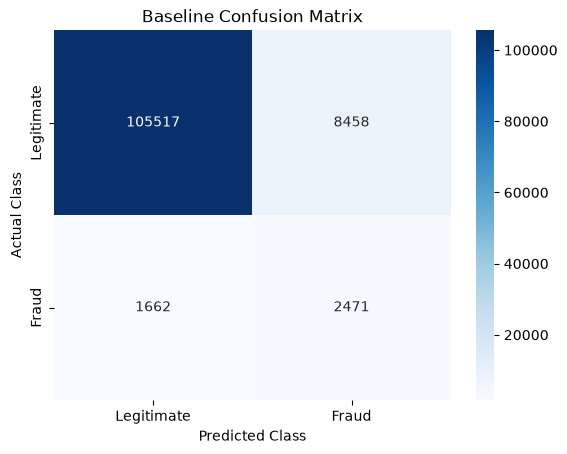

In [6]:
cm = confusion_matrix(y_test, y_pred)
tn, fp, fn, tp = cm.ravel()
print("TN:", tn)
print("FP:", fp)
print("FN:", fn)
print("TP:", tp)

sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=["Legitimate", "Fraud"], yticklabels=["Legitimate", "Fraud"])
plt.title("Baseline Confusion Matrix")
plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")
plt.show()

**Interpretation:** A false negative is a fraudulent transaction missed by the model; a false positive is a legitimate transaction incorrectly flagged. Both matter, but their business costs may differ.

## 7. Precision, Recall, F1, and Classification Report

In [7]:
precision = precision_score(y_test, y_pred, zero_division=0)
recall = recall_score(y_test, y_pred, zero_division=0)
f1 = f1_score(y_test, y_pred, zero_division=0)

print("Precision:", precision)
print("Recall:", recall)
print("F1-Score:", f1)
print("Classification report:")
print(classification_report(y_test, y_pred, target_names=["Legitimate", "Fraud"], zero_division=0))

Precision: 0.22609570866501968
Recall: 0.597870796031938
F1-Score: 0.3281104766963219
Classification report:
              precision    recall  f1-score   support

  Legitimate       0.98      0.93      0.95    113975
       Fraud       0.23      0.60      0.33      4133

    accuracy                           0.91    118108
   macro avg       0.61      0.76      0.64    118108
weighted avg       0.96      0.91      0.93    118108



**Interpretation:** Accuracy alone is insufficient for this imbalanced problem. Precision measures how many flagged transactions are truly fraud, recall measures how many actual fraud cases are detected, and F1 balances both.

## 8. ROC-AUC and PR-AUC

ROC-AUC: 0.8606540395418893
PR-AUC: 0.3997497915922183


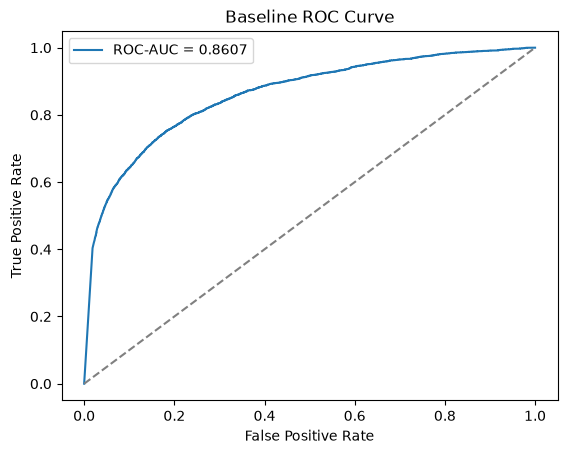

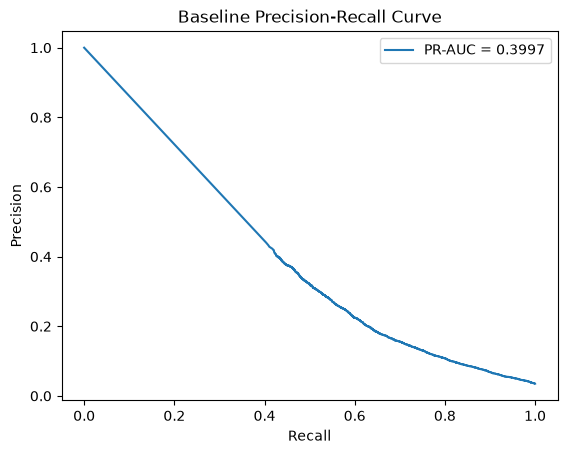

In [8]:
roc_auc = roc_auc_score(y_test, y_proba)
precision_curve, recall_curve, thresholds = precision_recall_curve(y_test, y_proba)
pr_auc = auc(recall_curve, precision_curve)

print("ROC-AUC:", roc_auc)
print("PR-AUC:", pr_auc)

fpr, tpr, _ = roc_curve(y_test, y_proba)
plt.plot(fpr, tpr, label=f"ROC-AUC = {roc_auc:.4f}")
plt.plot([0, 1], [0, 1], linestyle="--", color="gray")
plt.title("Baseline ROC Curve")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.legend()
plt.show()

plt.plot(recall_curve, precision_curve, label=f"PR-AUC = {pr_auc:.4f}")
plt.title("Baseline Precision-Recall Curve")
plt.xlabel("Recall")
plt.ylabel("Precision")
plt.legend()
plt.show()

**Interpretation:** ROC-AUC summarizes ranking performance across classification thresholds. PR-AUC is especially informative here because fraud is a minority class and focuses directly on precision-recall behavior.

## 9. Metric Summary

In [9]:
metrics_table = pd.DataFrame({
    "Metric": ["Precision", "Recall", "F1", "ROC-AUC", "PR-AUC"],
    "Value": [precision, recall, f1, roc_auc, pr_auc]
})
display(metrics_table)

,Metric,Value
0,Precision,0.226096
1,Recall,0.597871
2,F1,0.328110
3,ROC-AUC,0.860654
4,PR-AUC,0.399750


## 10. Diagnostic Threshold Analysis

In [10]:
threshold_rows = []
for threshold in [0.3, 0.5, 0.7]:
    threshold_pred = (y_proba >= threshold).astype(int)
    threshold_cm = confusion_matrix(y_test, threshold_pred)
    threshold_tn, threshold_fp, threshold_fn, threshold_tp = threshold_cm.ravel()
    threshold_rows.append({
        "Threshold": threshold,
        "Precision": precision_score(y_test, threshold_pred, zero_division=0),
        "Recall": recall_score(y_test, threshold_pred, zero_division=0),
        "F1": f1_score(y_test, threshold_pred, zero_division=0),
        "False Positives": threshold_fp,
        "False Negatives": threshold_fn
    })
threshold_table = pd.DataFrame(threshold_rows)
display(threshold_table)
print("This is diagnostic only. No final threshold was selected or optimized.")

,Threshold,Precision,Recall,F1,False Positives,False Negatives
0,0.3,0.222480,0.604404,0.325239,8730,1635
1,0.5,0.226096,0.597871,0.328110,8458,1662
2,0.7,0.230106,0.594000,0.331712,8214,1678


This is diagnostic only. No final threshold was selected or optimized.


**Baseline threshold:** The default model classifies according to its decision function, while this notebook also displays fixed probability cutoffs of 0.3, 0.5, and 0.7 for diagnostics only. Threshold optimization belongs to a later phase.

## 11. Simple Error Analysis

In [11]:
false_positive_indices = np.where((y_test.to_numpy() == 0) & (y_pred == 1))[0]
false_negative_indices = np.where((y_test.to_numpy() == 1) & (y_pred == 0))[0]

print("False positives:", len(false_positive_indices))
print("False negatives:", len(false_negative_indices))
print("Sample false-positive row indices:", false_positive_indices[:10].tolist())
print("Sample false-negative row indices:", false_negative_indices[:10].tolist())
print("These samples show row positions only; sensitive raw transaction fields are not exposed.")

False positives: 8458
False negatives: 1662
Sample false-positive row indices: [8, 11, 17, 26, 33, 35, 42, 71, 72, 83]
Sample false-negative row indices: [207, 255, 340, 449, 504, 509, 520, 624, 683, 714]
These samples show row positions only; sensitive raw transaction fields are not exposed.


**Interpretation:** False negatives are the most direct missed-fraud risk, while false positives can create customer friction or manual-review cost. The baseline errors motivate comparison with nonlinear models, but no such model is trained in this phase.

## 12. Baseline Findings and Limitations

In [12]:
print("Strengths:")
print("- Fast, simple, reproducible reference model.")
print("- Uses class_weight='balanced' without resampling.")
print("- Produces probabilities for risk scoring.")
print("Limitations:")
print("- Linear decision structure.")
print("- May not capture complex nonlinear relationships.")
print("- Performance depends on the current sparse feature representation.")
print("- Diagnostic thresholds are not optimized.")
print("Decision: use this model as a reference point for later advanced-model comparison.")

Strengths:
- Fast, simple, reproducible reference model.
- Uses class_weight='balanced' without resampling.
- Produces probabilities for risk scoring.
Limitations:
- Linear decision structure.
- May not capture complex nonlinear relationships.
- Performance depends on the current sparse feature representation.
- Diagnostic thresholds are not optimized.
Decision: use this model as a reference point for later advanced-model comparison.


## 13. Save the Baseline Model

In [13]:
models_folder = project / "models"
models_folder.mkdir(exist_ok=True)
baseline_path = models_folder / "baseline_sgd.pkl"
joblib.dump(baseline_model, baseline_path)
print("Saved:", baseline_path)
print("File exists:", baseline_path.exists())
print("File size in bytes:", baseline_path.stat().st_size)

Saved: C:\Users\HP\Desktop\fraud-detection-system\models\baseline_sgd.pkl
File exists: True
File size in bytes: 5078


## Phase 5 — Baseline Model Final Report

In [14]:
print("PHASE 5 — FINAL BASELINE REPORT")
print("=" * 45)
print("Dataset")
print("Training Samples:", X_train.shape[0])
print("Testing Samples:", X_test.shape[0])
print("Features:", X_train.shape[1])
print("\nModel")
print("Algorithm: SGDClassifier")
print("Loss: log_loss")
print("Class Weight: balanced")
print("Random State: 42")
print("\nResults")
print("Precision:", precision)
print("Recall:", recall)
print("F1:", f1)
print("ROC-AUC:", roc_auc)
print("PR-AUC:", pr_auc)
print("\nConfusion Matrix")
print("TN:", tn, "FP:", fp, "FN:", fn, "TP:", tp)
print("\nThreshold Diagnostic")
display(threshold_table)
print("\nError Analysis")
print("False Positives:", len(false_positive_indices))
print("False Negatives:", len(false_negative_indices))
print("\nReproducibility")
print("Training Data: X_train_processed and y_train")
print("Testing Data: X_test_processed and y_test")
print("Preprocessing: loaded from Phase 4 artifacts; not repeated")
print("Saved Model:", baseline_path)
print("\nFinal Decision")
print("The baseline is a valid reference model, but a more powerful nonlinear model is justified for comparison because fraud behavior may not be linear.")
print("No Random Forest, XGBoost, SMOTE, threshold optimization, SHAP, or deployment was performed.")

PHASE 5 — FINAL BASELINE REPORT
Dataset
Training Samples: 472432
Testing Samples: 118108
Features: 495

Model
Algorithm: SGDClassifier
Loss: log_loss
Class Weight: balanced
Random State: 42

Results
Precision: 0.22609570866501968
Recall: 0.597870796031938
F1: 0.3281104766963219
ROC-AUC: 0.8606540395418893
PR-AUC: 0.3997497915922183

Confusion Matrix
TN: 105517 FP: 8458 FN: 1662 TP: 2471

Threshold Diagnostic


,Threshold,Precision,Recall,F1,False Positives,False Negatives
0,0.3,0.222480,0.604404,0.325239,8730,1635
1,0.5,0.226096,0.597871,0.328110,8458,1662
2,0.7,0.230106,0.594000,0.331712,8214,1678



Error Analysis
False Positives: 8458
False Negatives: 1662

Reproducibility
Training Data: X_train_processed and y_train
Testing Data: X_test_processed and y_test
Preprocessing: loaded from Phase 4 artifacts; not repeated
Saved Model: C:\Users\HP\Desktop\fraud-detection-system\models\baseline_sgd.pkl

Final Decision
The baseline is a valid reference model, but a more powerful nonlinear model is justified for comparison because fraud behavior may not be linear.
No Random Forest, XGBoost, SMOTE, threshold optimization, SHAP, or deployment was performed.


**STOP:** Phase 5 is complete. Do not start `06_model_comparison.ipynb` until explicit approval.